# z021 - Curva promedio de N para juntar (método del tutor)

- **Modelo:** trial 34 de z005, target **BAJA+1 + BAJA+2**, lags y deltas 1 y 2 (igual que el submit 28).
- **Dos cortes:** train 202104 → valid 202106, y train 202103 → valid 202105. 5 semillas cada uno = 10 modelos.
- Para cada modelo: ordenar clientes por probabilidad y calcular la ganancia acumulada (curva de ganancia según N),
  usando `clase_ternaria` (BAJA+2 = +1.072.500; el resto = −27.500).
- Promediar las curvas y tomar el máximo del promedio → N candidato.

In [1]:
# --- 1. Librerías y parámetros ---
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO   = 27_500
SEMILLAS = [270131, 417293, 583117, 692347, 851071]
CORTES   = {"junio": (202104, 202106), "mayo": (202103, 202105)}   # nombre: (mes train, mes valid)

params_fijos = {
    "objective": "binary", "learning_rate": 0.005, "min_data_in_leaf": 0,
    "feature_fraction": 0.5, "feature_fraction_bynode": 0.2, "max_bin": 31, "verbose": -1,
}
elegidos = pd.read_csv("z005_top10_final.csv", sep=";", decimal=",", encoding="utf-8-sig", index_col="trial")
r = elegidos.loc[34]
params = {**params_fijos, "num_leaves": int(r["params_num_leaves"]),
          "min_sum_hessian_in_leaf": float(r["params_min_sum_hessian_in_leaf"])}
N_ARBOLES = int(r["user_attrs_best_iter"])   # best_iter de Optuna (entrenado con 1 mes, como acá)
params, N_ARBOLES

({'objective': 'binary',
  'learning_rate': 0.005,
  'min_data_in_leaf': 0,
  'feature_fraction': 0.5,
  'feature_fraction_bynode': 0.2,
  'max_bin': 31,
  'verbose': -1,
  'num_leaves': 137,
  'min_sum_hessian_in_leaf': 9.755574121446362},
 538)

In [2]:
# --- 2. Cargar datos y lags/deltas de orden 1 y 2 ---
df = pd.read_parquet("../competencia_01.parquet")
df["clase_binaria2"] = df["clase_ternaria"].isin(["BAJA+1", "BAJA+2"]).astype(int)

no_usar = ["foto_mes", "clase_ternaria", "clase_binaria2"]
cols = [c for c in df.columns if c not in no_usar and c != "numero_de_cliente"]

df = df.sort_values(["numero_de_cliente", "foto_mes"]).reset_index(drop=True)
grupo = df.groupby("numero_de_cliente")[cols]
nuevas = []
for k in [1, 2]:
    lag = grupo.shift(k).astype("float32")
    delta = (df[cols] - lag).astype("float32")
    lag.columns   = [f"{c}_lag{k}" for c in cols]
    delta.columns = [f"{c}_delta{k}" for c in cols]
    nuevas += [lag, delta]
df = pd.concat([df] + nuevas, axis=1)
del nuevas, lag, delta, grupo
variables = [c for c in df.columns if c not in no_usar]
print("Variables:", len(variables))

Variables: 761


In [3]:
# --- 3. Entrenar y calcular la curva de ganancia de cada modelo ---
# Curva: ganancia acumulada si mando los N clientes con mayor probabilidad (N = 1, 2, 3, ...)
curvas = {}
for corte, (mes_train, mes_valid) in CORTES.items():
    train = df[df["foto_mes"] == mes_train]
    valid = df[df["foto_mes"] == mes_valid]
    datos = lgb.Dataset(train[variables], label=train["clase_binaria2"])
    # Ganancia de cada cliente si lo estimulo
    gan_cliente = np.where(valid["clase_ternaria"] == "BAJA+2", GANANCIA_ACIERTO, -COSTO_ESTIMULO)
    for semilla in SEMILLAS:
        inicio = time.time()
        modelo = lgb.train({**params, "seed": semilla}, datos, num_boost_round=N_ARBOLES)
        prob = modelo.predict(valid[variables])
        orden = np.argsort(-prob)                         # de mayor a menor probabilidad
        curvas[(corte, semilla)] = np.cumsum(gan_cliente[orden])
        c = curvas[(corte, semilla)]
        print(f"{corte} semilla {semilla}: máx {c.max()/1e6:.1f} M en N = {c.argmax()+1} "
              f"({time.time()-inicio:.0f} s)", flush=True)

junio semilla 270131: máx 419.9 M en N = 15132 (22 s)


junio semilla 417293: máx 424.5 M en N = 14563 (21 s)


junio semilla 583117: máx 415.8 M en N = 13921 (21 s)


junio semilla 692347: máx 415.9 M en N = 14956 (20 s)


junio semilla 851071: máx 417.0 M en N = 14718 (20 s)


mayo semilla 270131: máx 276.6 M en N = 8460 (15 s)


mayo semilla 417293: máx 274.6 M en N = 8653 (11 s)


mayo semilla 583117: máx 276.2 M en N = 6957 (11 s)


mayo semilla 692347: máx 269.8 M en N = 6708 (11 s)


mayo semilla 851071: máx 274.0 M en N = 7718 (11 s)


In [4]:
# --- 4. Promedios y N óptimo ---
# Los meses tienen distinta cantidad de clientes: recortamos al largo mínimo
largo = min(len(c) for c in curvas.values())
prom = {corte: np.mean([curvas[(corte, s)][:largo] for s in SEMILLAS], axis=0) for corte in CORTES}
prom["general"] = np.mean([prom[c] for c in CORTES], axis=0)

resumen = []
for nombre, c in prom.items():
    n_max = c.argmax() + 1
    # Meseta: N donde la curva está a menos de 1 M del máximo
    meseta = np.where(c >= c.max() - 1e6)[0] + 1
    resumen.append({"curva": nombre, "N_max": n_max, "ganancia_max_M": round(c.max() / 1e6, 1),
                    "meseta_desde": meseta.min(), "meseta_hasta": meseta.max()})
resumen = pd.DataFrame(resumen)
# Ganancia promedio en los N que mandamos al público
for n in [10_000, 10_500, 11_000, 11_500, 12_000, 12_500, 13_000, 14_000]:
    resumen[f"N{n}"] = [round(prom[k][n - 1] / 1e6, 1) for k in prom]
resumen.to_csv("z021_curva_n_juntar.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
resumen

,curva,N_max,ganancia_max_M,meseta_desde,meseta_hasta,N10000,N10500,N11000,N11500,N12000,N12500,N13000,N14000
0,junio,15142,415.6,14257,15290,367.6,371.9,374.7,380.5,385.7,390.8,398.2,413.4
1,mayo,6802,271.2,6645,7334,261.6,257.3,255.2,253.6,250.8,246.3,239.8,227.9
2,general,13968,321.3,13676,14084,314.6,314.6,314.9,317.0,318.2,318.6,319.0,320.6


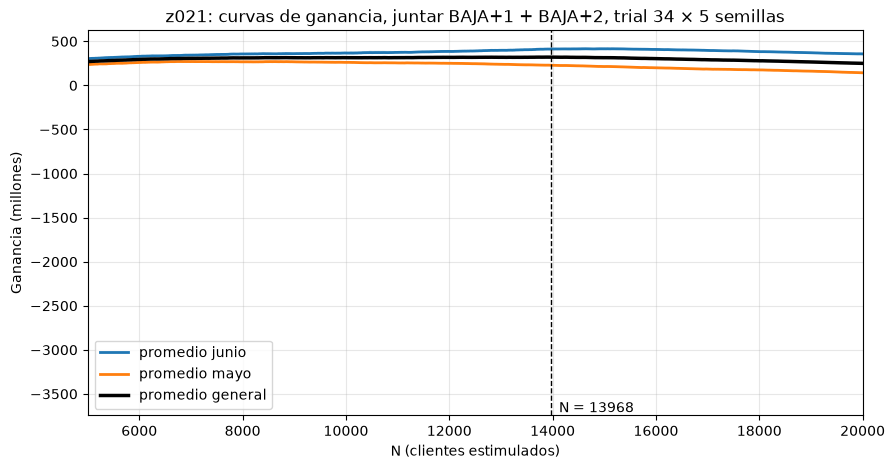

In [5]:
# --- 5. Gráfico ---
x = np.arange(1, largo + 1)
fig, ax = plt.subplots(figsize=(10, 5))
colores = {"junio": "tab:blue", "mayo": "tab:orange"}
for (corte, s), c in curvas.items():
    ax.plot(x, c[:largo] / 1e6, color=colores[corte], alpha=0.25, lw=0.8)
for corte in CORTES:
    ax.plot(x, prom[corte] / 1e6, color=colores[corte], lw=2, label=f"promedio {corte}")
ax.plot(x, prom["general"] / 1e6, color="black", lw=2.5, label="promedio general")
n_opt = prom["general"].argmax() + 1
ax.axvline(n_opt, color="black", ls="--", lw=1)
ax.text(n_opt, ax.get_ylim()[0], f"  N = {n_opt}", va="bottom")
ax.set_xlim(5_000, 20_000)
ax.set_xlabel("N (clientes estimulados)"); ax.set_ylabel("Ganancia (millones)")
ax.set_title("z021: curvas de ganancia, juntar BAJA+1 + BAJA+2, trial 34 × 5 semillas")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig("z021_curva_n_juntar.png", dpi=120, bbox_inches="tight")

## Conclusiones (08/10)
Corrió en 2,9 min. Mejor N por semilla:
- **Junio:** 13.900 a 15.100 (máx ~416-424 M). Promedio: N 15.142, 415,6 M.
- **Mayo:** 6.700 a 8.650 (máx ~270-277 M). Promedio: N 6.802, 271,2 M.
- **General:** N 13.968, 321,3 M, pero la curva es casi plana entre 10.000 (314,6) y 14.000 (320,6). El máximo general
  lo arrastra junio porque gana más millones.

**Los meses no coinciden:** el mejor N depende de cuántas BAJA+2 tiene el mes (mayo 870 → ~7.000; junio 1098 → ~15.000).

Pérdida respecto del óptimo de cada mes (millones):
| N | junio | mayo | peor caso |
|---|---|---|---|
| 10.000 | −48 | −10 | −48 |
| 11.000 | −41 | −16 | −41 |
| 12.000 | −30 | −20 | −30 |
| **12.500** | −25 | −25 | **−25** |
| 13.000 | −17 | −31 | −31 |
| 14.000 | −2 | −43 | −43 |

**12.000-12.500 es lo que menos arriesga** sin saber a qué mes se parece agosto. El público de agosto (submits 18-28)
tiene meseta 10.500-12.000. **Recomendación: quedarse con 12.000 (submit 28).**

Nota: el gráfico sale aplastado (el eje Y llega a −3.500 M por las curvas completas); falta poner `ax.set_ylim`.